In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)

print("libraries imported successfully")

libraries imported successfully


In [ ]:
df = pd.read_csv("/content/telco customer curn.csv")
print("dataset loaded successfully")
print("number of rows:", df.shape[0])
print("number of columns:", df.shape[1])

df.head(10)

dataset loaded successfully
number of rows: 7043
number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
missing_values = df.isnull().sum()

print("missing values:")
missing_values[missing_values > 0]

missing values:


,0


In [ ]:
duplicate_rows = df.duplicated()
print("number of duplicate rows:", duplicate_rows)

number of duplicate rows: 0       False
1       False
2       False
3       False
4       False
        ...  
7038    False
7039    False
7040    False
7041    False
7042    False
Length: 7043, dtype: bool


,count
Churn,
No,5174
Yes,1869


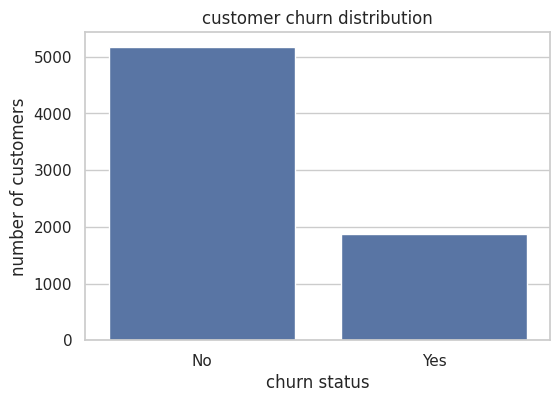

In [ ]:
churn_count = df["Churn"].value_counts()
display(churn_count)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")

plt.title("customer churn distribution")
plt.xlabel("churn status")
plt.ylabel("number of customers")
plt.show()

In [ ]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100
churn_percentage.round(2)

,proportion
Churn,
No,73.46
Yes,26.54


In [ ]:
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\n sample values:")
df["TotalCharges"].head(10)

TotalCharges data type:
object

 sample values:


,TotalCharges
0,29.85
1,1889.5
2,108.15
3,1840.75
4,151.65
5,820.5
6,1949.4
7,301.9
8,3046.05
9,3487.95


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

print("missing values after conversion:")
print(df["TotalCharges"].isnull().sum())

missing values after conversion:
11


In [ ]:
missing_data = df[df["TotalCharges"].isnull()]
missing_data

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [ ]:
df = df.dropna(subset=["TotalCharges"])
df = df.reset_index(drop=True)

print("dataset shape after cleaning:", df.shape)
print("remaining missing values:", df.isnull().sum().sum())

dataset shape after cleaning: (7032, 21)
remaining missing values: 0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


In [ ]:
churn_count = df["Churn"].value_counts()
display(churn_count)

churn_rate = (df["Churn"] == 'Yes').mean() *100
print(f"Customer churn rate: {churn_rate:.2f}%")

,count
Churn,
No,5163
Yes,1869


Customer churn rate: 26.58%


# **EXPLORATORY DATA ANALYSIS (EDA)**

## **OVERALL CUSTOMER CHURN RATE**

In [ ]:
churn_count = df["Churn"].value_counts()
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

churn_summary = pd.DataFrame({
    "total customers" : churn_count,
    "percentage": churn_percentage.round(2)
})

churn_summary

,total customers,percentage
Churn,,
No,5163,73.42
Yes,1869,26.58


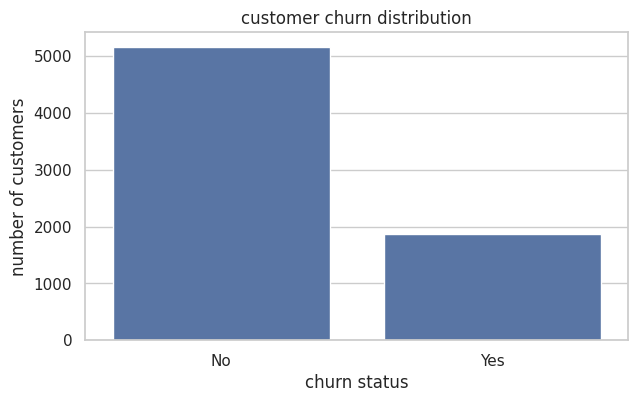

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Churn")

plt.title("customer churn distribution")
plt.xlabel("churn status")
plt.ylabel("number of customers")
plt.show()

## **CUSTOMER CHURN BY CONTRACT TYPE**

In [ ]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize = "index"
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.72,11.28
Two year,97.15,2.85


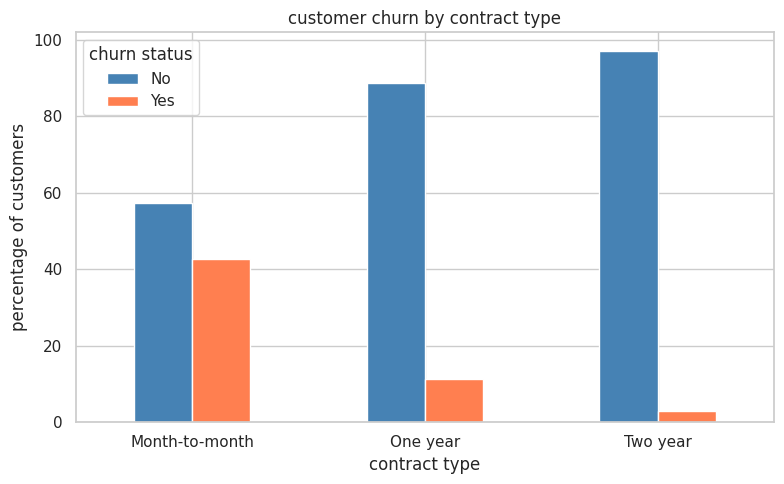

In [ ]:
contract_churn.plot(
    kind="bar",
    stacked=False,
    figsize=(8, 5),
    color=["steelblue", "coral"]

)

plt.title("customer churn by contract type")
plt.xlabel("contract type")
plt.ylabel("percentage of customers")
plt.legend(title="churn status")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **CUSTOMER CHURN BY TENURE**

Text(0, 0.5, 'average tenure (months)')

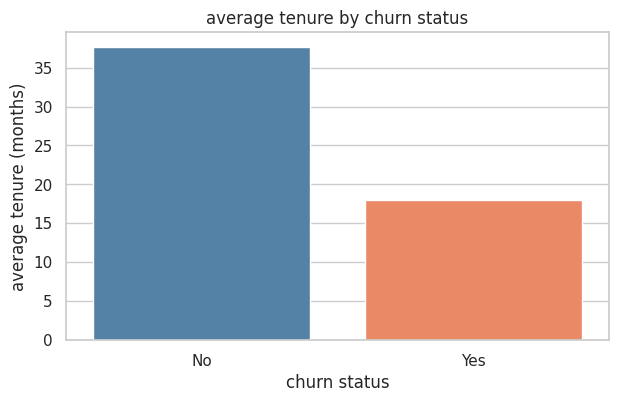

In [ ]:
tenure_summary = df.groupby("Churn")["tenure"].mean().reset_index()

plt.figure(figsize=(7, 4))

sns.barplot(
    data=tenure_summary,
    x="Churn",
    y="tenure",
    hue="Churn",
    palette={"No": "steelblue", "Yes": "coral"},
    legend=False
)

plt.title("average tenure by churn status")
plt.xlabel("churn status")
plt.ylabel("average tenure (months)")

In [ ]:
tenure_summary.round(2)

,Churn,tenure
0,No,37.65
1,Yes,17.98


## **CUSTOMER CHURN BY MONTHLY CHARGES**

Text(0, 0.5, 'average monthly charges ($)')

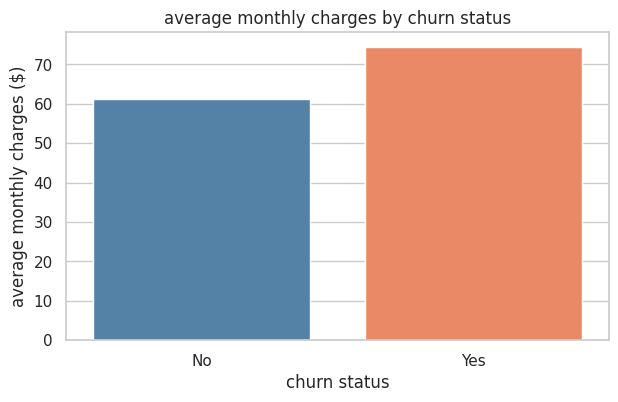

In [ ]:
charges_summary = df.groupby("Churn")["MonthlyCharges"].mean().reset_index()

plt.figure(figsize=(7, 4))

sns.barplot(
    data=charges_summary,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette={"No": "steelblue", "Yes": "coral"},
    legend=False
)

plt.title("average monthly charges by churn status")
plt.xlabel("churn status")
plt.ylabel("average monthly charges ($)")

In [ ]:
charges_summary.round(2)

,Churn,MonthlyCharges
0,No,61.31
1,Yes,74.44


# **STATISTICAL ANALYSIS**

## **CHI-SQUARE TEST: CONTRACT AND CHURN**

In [ ]:
from scipy.stats import chi2_contingency

contract_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

chi2, p_value, dof, expected = chi2_contingency(contract_table)
print("Chi-Square Statistic:", round(chi2, 4))
print("P-value:", p_value)

if p_value < 0.05:
  print("there is a significant association between contract type and churn")
else:
  print("there is no significant association between contract type and churn")

Chi-Square Statistic: 1184.5966
P-value: 5.863038300673391e-258
there is a significant association between contract type and churn


## **MANN-WHITNEY U TEST: TENURE AND CHURN**

In [ ]:
from scipy.stats import mannwhitneyu

tenure_no = df[df["Churn"] == "No"]["tenure"]
tenure_yes = df[df["Churn"] == "Yes"]["tenure"]

stat, p_value = mannwhitneyu(
    tenure_no,
    tenure_yes,
    alternative="two-sided"
)

print("Mann-Whitney U Statictic:", round(stat, 2))
print("P-value:", p_value)

if p_value < 0.05:
  print("there is a significant difference in customer tenure")
else:
  print("there is no significant difference in customer tenure")


Mann-Whitney U Statictic: 7154668.0
P-value: 2.419635517951866e-208
there is a significant difference in customer tenure


In [ ]:
tenure_summary = df.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median"]
)

tenure_summary.round(2)

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


## **MANN-WHITNEY U TEST: MONTHLY CHARGES AND CHURN**

In [ ]:
from scipy.stats import mannwhitneyu

charges_no = df[df["Churn"] == "No"]["MonthlyCharges"]
charges_yes = df[df["Churn"] == "Yes"]["MonthlyCharges"]


stat, p_value = mannwhitneyu(
    charges_no,
    charges_yes,
    alternative="two-sided"
)

print("Mann-Whitney U Statistic:", round(stat, 2))
print("P-value:", p_value)

if p_value < 0.05:
    print("There is a significant difference in monthly charges.")
else:
    print("There is no significant difference in monthly charges.")

Mann-Whitney U Statistic: 3667080.5
P-value: 3.311627651988585e-54
There is a significant difference in monthly charges.


In [ ]:
charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median"]
)

display(charges_summary.round(2))

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


# **DATA PREPROCESSING**

## **FEATURE SELECTION**

In [ ]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

print("Number of features:", X.shape[1])
print("Number of target records:", y.shape[0])

Number of features: 19
Number of target records: 7043


## **TRAIN TEST SPLIT**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


## **IDENTIFIKASI FITUR**

In [ ]:
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

print("Numerical columns:")
print(list(num_cols))

print("\nCategorical columns:")
print(list(cat_cols))

Numerical columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical columns:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


## **DATA TRANSFORMASI**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Preprocessing for numerical features

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df[["MonthlyCharges", "TotalCharges"]].dtypes)

MonthlyCharges    float64
TotalCharges      float64
dtype: object


In [ ]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

# Split the data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify feature types

num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

print("Numerical features:", list(num_cols))
print("Categorical features:", list(cat_cols))

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [ ]:
# Preprocessing for numerical features

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing is ready.")

Preprocessing is ready.


# **MODELING**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Define the models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    )
}

print("Three models are ready.")

Three models are ready.


In [ ]:
model_pipelines = {}

for name, model in models.items():

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    model_pipelines[name] = model_pipeline

print("All model pipelines are ready.")

All model pipelines are ready.


In [ ]:
for name, model_pipeline in model_pipelines.items():

    model_pipeline.fit(X_train, y_train)

    print(name, "training completed.")

Logistic Regression training completed.
Decision Tree training completed.
Random Forest training completed.


# **MODEL EVALUATION**

In [ ]:
predictions = {}

for name, model_pipeline in model_pipelines.items():
    y_pred = model_pipeline.predict(X_test)
    predictions[name] = y_pred
    print(name, "prediction completed.")

Logistic Regression prediction completed.
Decision Tree prediction completed.
Random Forest prediction completed.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store model evaluation results

results = []

for name, model_pipeline in model_pipelines.items():

    y_pred = predictions[name]

    # Get churn probability
    churn_index = list(
        model_pipeline.classes_
    ).index("Yes")

    y_prob = model_pipeline.predict_proba(X_test)[:, churn_index]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="Yes"
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label="Yes"
        ),
        "ROC-AUC": roc_auc_score(
            (y_test == "Yes").astype(int), y_prob
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(3).sort_values(
        by="Recall", ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Decision Tree,0.728,0.488,0.481,0.485,0.650
2,Random Forest,0.783,0.618,0.476,0.538,0.822


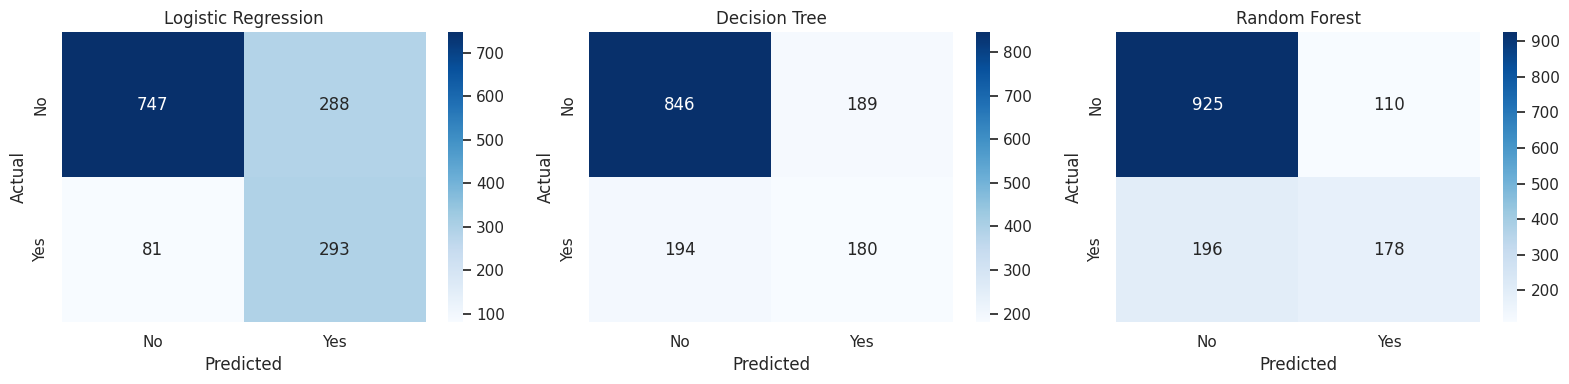

In [ ]:
from sklearn.metrics import confusion_matrix

# Compare confusion matrix for each model

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, y_pred) in zip(
    axes, predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["No", "Yes"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No", "Yes"],
        yticklabels=["No", "Yes"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

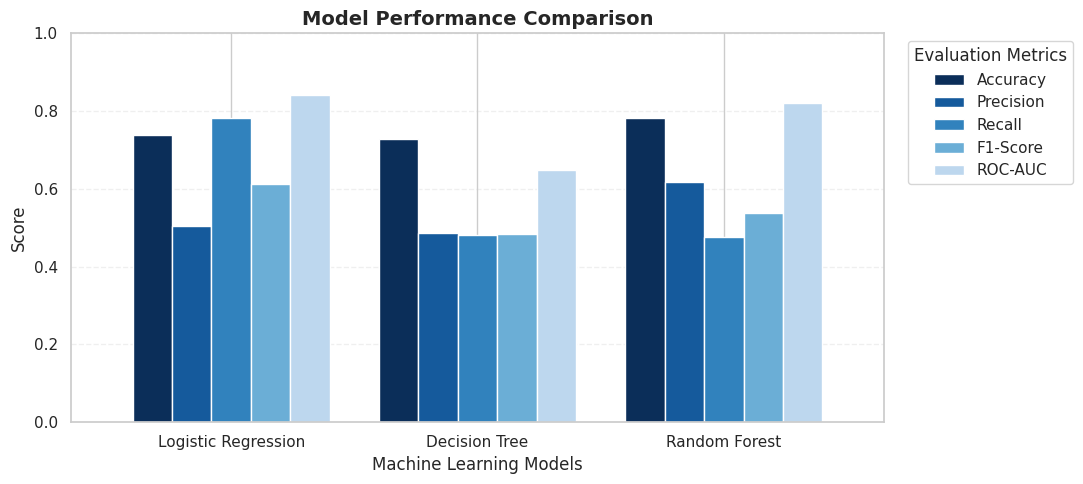

In [ ]:
# Compare model performance

comparison = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
]

# Blue color gradient
blue_colors = [
    "#0B2E59",  # Dark blue
    "#155A9C",  # Deep blue
    "#3182BD",  # Medium blue
    "#6BAED6",  # Light blue
    "#BDD7EE"   # Very light blue
]

ax = comparison.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8,
    color=blue_colors,
    edgecolor="white"
)

plt.title("Model Performance Comparison", fontsize=14, fontweight="bold")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")

plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Identify the model with the highest recall

best_model_name = results_df.loc[
    results_df["Recall"].idxmax(), "Model"
]

print("Model with the highest recall:", best_model_name)

Model with the highest recall: Logistic Regression


# **THRESHOLD ANALYSIS**

In [ ]:
lr_model = model_pipelines["Logistic Regression"]
churn_index = list(lr_model.classes_).index("Yes")
lr_prob = lr_model.predict_proba(X_test)[:, churn_index]

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Compare different classification thresholds

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []
for threshold in thresholds:

    y_pred_threshold = np.where(
        lr_prob >= threshold, "Yes", "No"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, y_pred_threshold, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, pos_label="Yes"
        ),
        "F1-Score": f1_score(
            y_test, y_pred_threshold, pos_label="Yes"
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Precision,Recall,F1-Score
0,0.3,0.429,0.928,0.587
1,0.4,0.466,0.866,0.606
2,0.5,0.504,0.783,0.614
3,0.6,0.540,0.706,0.612
4,0.7,0.603,0.602,0.602


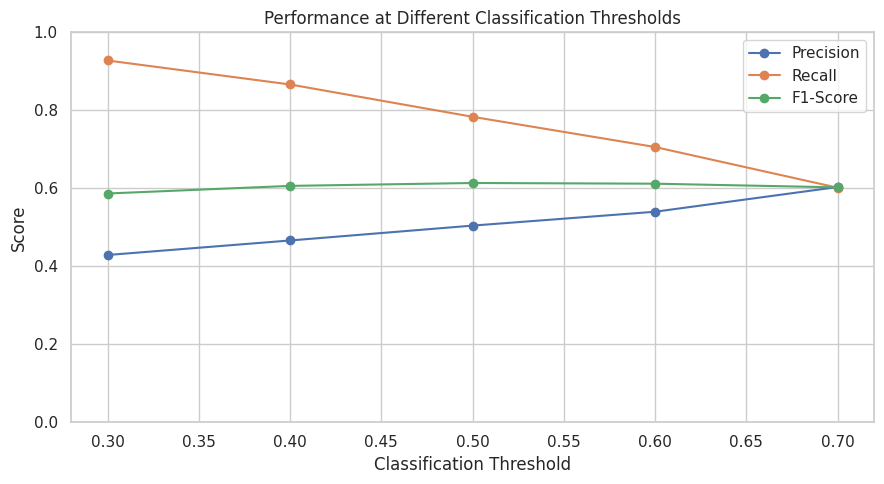

In [ ]:
# Visualize threshold performance

threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1-Score"]
].plot(
    marker="o",
    figsize=(9, 5)
)

plt.title("Performance at Different Classification Thresholds")
plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

# **FEATURE IMPORTANCE**

In [ ]:
# Get feature names after preprocessing

feature_names = (
    lr_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Logistic Regression coefficients

coefficients = (
    lr_model.named_steps["classifier"].coef_[0]
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Coefficient",
    ascending=False
)

display(feature_importance.head(15).round(3))

,Feature,Coefficient,Absolute Coefficient
1,num__tenure,-1.124,1.124
38,cat__Contract_Two year,-0.781,0.781
16,cat__InternetService_Fiber optic,0.705,0.705
2,num__MonthlyCharges,-0.664,0.664
36,cat__Contract_Month-to-month,0.663,0.663
15,cat__InternetService_DSL,-0.621,0.621
3,num__TotalCharges,0.457,0.457
35,cat__StreamingMovies_Yes,0.275,0.275
25,cat__DeviceProtection_No internet service,-0.275,0.275
17,cat__InternetService_No,-0.275,0.275


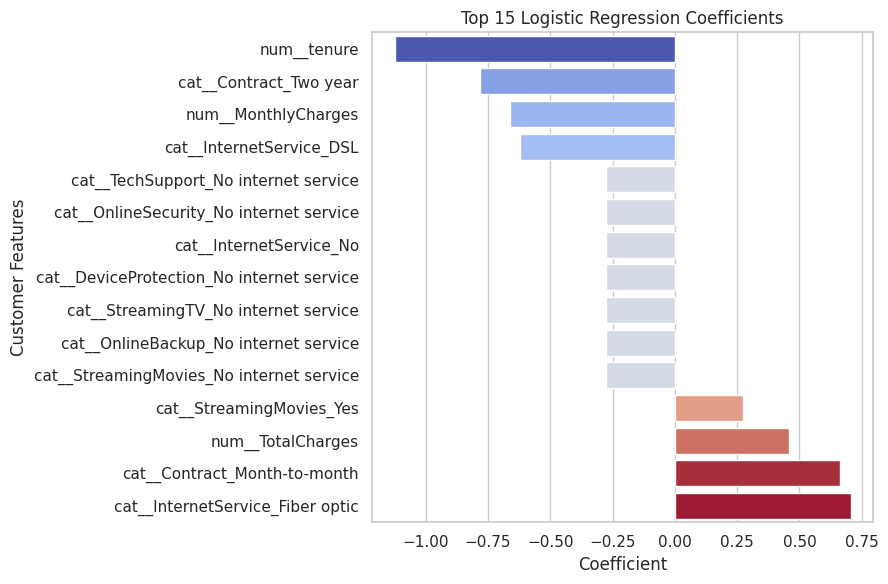

In [ ]:
# Visualize the most important coefficients

top_features = feature_importance.head(15).sort_values(
    "Coefficient"
)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="coolwarm",
    legend=False
)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Customer Features")

plt.tight_layout()
plt.show()

# **KEY FINDINGS**

1. The analysis shows that customer tenure and contract type are important factors associated with churn predictions.

2. Customers with shorter tenure and month-to-month contracts tend to have higher churn probabilities in the Logistic Regression model.

3. The threshold analysis also shows a trade-off between precision and recall. A lower threshold identifies more customers who actually churned, while a higher threshold produces more selective predictions.

# **BUSINESS IMPLICATIONS**

1. Based on these findings, the company may focus on improving the experience of new customers and developing retention programs for customers with month-to-month contracts.

2. The company may also evaluate its fiber optic services to better understand the higher churn risk associated with this customer group.

3. These recommendations should be tested through further business evaluation before implementation.

# **BUSINESS RECOMMENDATIONS**

1. Improve Customer Onboarding: Provide better guidance and support for new customers to improve their early subscription experience.

2. Encourage Long-Term Contracts: Offer attractive benefits or discounts to customers who choose longer subscription periods.

3. Evaluate Fiber Optic Services: Review service quality, customer complaints, and satisfaction levels among fiber optic users.

4. Develop Customer Retention Programs: Use the Logistic Regression model to identify customers with high churn probabilities and prioritize retention efforts.

# **PROJECT CONCLUSION**

1. This project developed and evaluated three machine learning classification models to predict customer churn. Based on the evaluation results, Logistic Regression achieved the highest recall of 78.3% at the default classification threshold.

2. The findings show that customer tenure and contract type are important factors associated with churn predictions. These insights can help the company identify customers at risk of leaving and develop more targeted retention strategies.

3. Overall, this project demonstrates how data analysis and machine learning can support customer retention decisions.